<center>
    <p style="color: red; font-size: 20px;">Tên: Lê Thiên Hạo</p>
</center>
<center>
    <p style="color: red; font-size: 20px;">MSSV: 089206010393</p>
</center>

In [1]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)

In [2]:
cancer.data.head(20)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.26540,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.18600,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.24300,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.25750,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.16250,0.2364,0.07678
5,12.45,15.70,82.57,477.1,0.12780,0.17000,0.15780,0.08089,0.2087,0.07613,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.17410,0.3985,0.12440
6,18.25,19.98,119.60,1040.0,0.09463,0.10900,0.11270,0.07400,0.1794,0.05742,...,22.88,27.66,153.20,1606.0,0.1442,0.2576,0.3784,0.19320,0.3063,0.08368
7,13.71,20.83,90.20,577.9,0.11890,0.16450,0.09366,0.05985,0.2196,0.07451,...,17.06,28.14,110.60,897.0,0.1654,0.3682,0.2678,0.15560,0.3196,0.11510
8,13.00,21.82,87.50,519.8,0.12730,0.19320,0.18590,0.09353,0.2350,0.07389,...,15.49,30.73,106.20,739.3,0.1703,0.5401,0.5390,0.20600,0.4378,0.10720
9,12.46,24.04,83.97,475.9,0.11860,0.23960,0.22730,0.08543,0.2030,0.08243,...,15.09,40.68,97.65,711.4,0.1853,1.0580,1.1050,0.22100,0.4366,0.20750


In [3]:
cancer.target.value_counts()

target
1    357
0    212
Name: count, dtype: int64

# 3. Tách dữ liệu thành hai phần: training data(70%) và test data (30%

In [4]:
from sklearn.model_selection import train_test_split
train_x , test_x, train_y, test_y  = train_test_split(cancer.data, cancer.target, test_size= 0.3)

# 4. Chuẩn hóa dữ liệu với StandardScaler

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
fitted_train_x = scaler.fit_transform(train_x)
fitted_test_x = scaler.fit_transform(test_x)

# 5. Tạo và huấn luyện mô hình với training data

In [6]:
from sklearn.tree import DecisionTreeClassifier
tree_clf = DecisionTreeClassifier(max_depth=2) 
tree_clf.fit(fitted_train_x, train_y)

,criterion,'gini'
,splitter,'best'
,max_depth,2
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [7]:
!dot -Tpng cancer.dot -o cancer.png

In [8]:
pred = tree_clf.predict(fitted_test_x)

In [13]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(test_y, pred))

              precision    recall  f1-score   support

           0       0.98      0.77      0.86        70
           1       0.86      0.99      0.92       101

    accuracy                           0.90       171
   macro avg       0.92      0.88      0.89       171
weighted avg       0.91      0.90      0.90       171



In [12]:
confusion_matrix(test_y, pred)

array([[ 54,  16],
       [  1, 100]])

In [11]:
from sklearn.tree import export_graphviz
export_graphviz(
    tree_clf,
    out_file="cancer.dot",
    feature_names=train_x.columns,
    rounded=True,
    filled=True
)

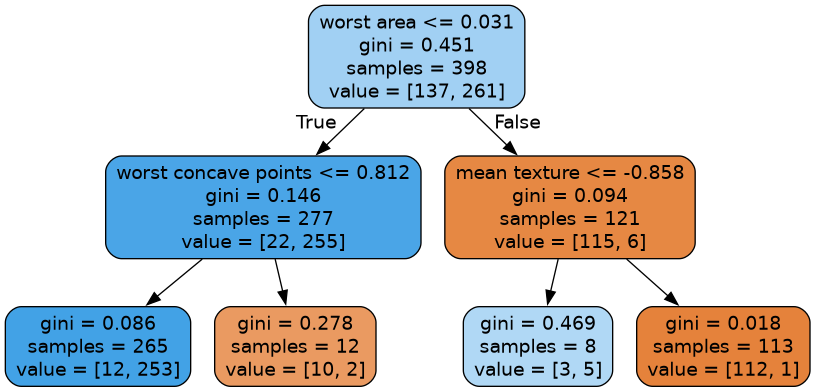